# Perfil da urna × voto: válidos e eleitores aptos (2º turno, 2022 e 2026)

Pergunta: a relação entre a baixa escolaridade da urna e o voto muda quando o
denominador deixa de ser o total de votos válidos e passa a ser o **total de
eleitores aptos** da urna? Com os aptos, a abstenção e os brancos e nulos entram
na conta e o voto de cada candidato fica dividido em quatro partes que somam 100%:
**PT + bolsonarista + brancos e nulos + abstenção**.

- **Unidade**: a urna (seção principal + agregadas), do Presidente, 2º turno.
- **`pobres`**: % de eleitores do cadastro analfabetos, que leem e escrevem ou com
  fundamental incompleto (a definição da planilha de 2018 do Sergio Simoni Jr.).
- Base: `urna_aptos_base.ipynb` (uma execução por ano).

**Como ler.** Os dados são agregados: os coeficientes são **associações
condicionais entre o perfil da urna e o resultado dela**, não efeitos nem
comportamento individual (falácia ecológica). A escolaridade do cadastro é a
declarada no alistamento e quase nunca é atualizada.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ / "src"))

from eleicoes import urna  # noqa: E402
from eleicoes.config import BRUTO_DIR, PROCESSADO_DIR  # noqa: E402
from eleicoes.cores import RAMPA_BOLSONARO, RAMPA_CINZA, RAMPA_PT  # noqa: E402

URNA_DIR = RAIZ / "dados" / "04_analise" / "urna"
FIG_DIR = URNA_DIR / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)
ANOS = (2022, 2026)
CHAVE = ["cd_mun_tse", "nr_zona", "nr_secao"]
PARTES = {
    "pc_aptos_pt": "PT (Lula)",
    "pc_aptos_bolso": "Bolsonarista",
    "pc_aptos_branco_nulo": "Brancos e nulos",
    "pc_aptos_abstencao": "Abstenção",
}
COR = {
    "pc_aptos_pt": RAMPA_PT[2], "pc_aptos_bolso": RAMPA_BOLSONARO[2],
    "pc_aptos_branco_nulo": RAMPA_CINZA[0], "pc_aptos_abstencao": RAMPA_CINZA[2],
}
REFERENCIA_SERGIO = {2018: (-0.601, 0.295, 448_827), 2022: (-0.489, 0.234, 460_083)}


def le_base(ano):
    d = pd.read_parquet(URNA_DIR / f"urna_presidente_{ano}_t2.parquet")
    return d.loc[d["motivo_exclusao"] == ""].copy()


base = {ano: le_base(ano) for ano in ANOS}
pd.DataFrame({ano: {"urnas": len(d), "aptos": d["qt_aptos"].sum()} for ano, d in base.items()}).T


def reg(df, y, x="pobres", controles=(), peso=None, fe=None, cluster=True):
    """MQO de `y` em `x` (+ controles). Erro agrupado por município; `fe` tira a média do grupo."""
    cols = list(dict.fromkeys([y, x, *controles, "cd_mun_tse", *([peso] if peso else []), *([fe] if fe else [])]))
    d = df[cols].replace([np.inf, -np.inf], np.nan).dropna()
    Y, X = d[y], d[[x, *controles]]
    if fe:
        Y = Y - Y.groupby(d[fe]).transform("mean")
        X = X - X.groupby(d[fe]).transform("mean")
    else:
        X = sm.add_constant(X)
    modelo = sm.WLS(Y, X, weights=d[peso]) if peso else sm.OLS(Y, X)
    if cluster:
        ajuste = modelo.fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d["cd_mun_tse"])[0]})
    else:
        ajuste = modelo.fit()
    return {"beta": ajuste.params[x], "ep": ajuste.bse[x], "r2_aj": ajuste.rsquared_adj, "n": int(ajuste.nobs)}

## 1. Replicação da planilha de 2018

Antes de qualquer resultado novo: a planilha de 2018 (448.827 seções) reproduz a
Tabela 1 do artigo? (MQO simples, voto de Bolsonaro nos válidos contra `pobres`.)

In [2]:
p18 = urna.le_planilha_2018(BRUTO_DIR / "elei_18_2t_escolaridade.xlsx", PROCESSADO_DIR / "aux" / "planilha_2018_secao.parquet")
r18 = reg(p18, "bolso", cluster=False)
ref = REFERENCIA_SERGIO[2018]
print(f"2018: β = {r18['beta']:.3f} (artigo {ref[0]}), R² aj. = {r18['r2_aj']:.3f} ({ref[1]}), N = {r18['n']:,} ({ref[2]:,})")
assert abs(r18["beta"] - ref[0]) < 0.001 and r18["n"] == ref[2]

mais_votos = p18["qt_validos"] > p18["qt_perfil"]
print(f"Linhas com mais votos válidos que eleitores no perfil: {mais_votos.sum():,} ({mais_votos.mean():.2%}) — "
      "são as seções agregadas: o voto sai na principal e o perfil foi casado seção a seção.")

2018: β = -0.601 (artigo -0.601), R² aj. = 0.295 (0.295), N = 448,827 (448,827)
Linhas com mais votos válidos que eleitores no perfil: 16,965 (3.78%) — são as seções agregadas: o voto sai na principal e o perfil foi casado seção a seção.


## 2. Tabela 1 por urna, sobre os válidos

O mesmo modelo (voto bolsonarista nos válidos contra `pobres`) com a urna como
unidade. A coluna "seção a seção" refaz a conta do jeito da planilha (só as
seções principais, com o perfil delas, sem as agregadas) para mostrar quanto as
agregadas mudam o resultado. O artigo traz −0,489 e R² aj. 0,234 (N = 460.083)
para 2022 com o casamento dele; aqui não é a mesma base, então os números só
precisam ser próximos.

In [3]:
def perfil_secao(ano):
    arqs = sorted((PROCESSADO_DIR / "perfil").glob(f"perfil_secao_{ano}_*.parquet"))
    ps = pd.concat([pd.read_parquet(a) for a in arqs], ignore_index=True)
    inf = ps[[f"qt_esc_{c}" for c in range(1, 9)]].sum(axis=1).replace(0, np.nan)
    ps["pobres_secao"] = 100 * ps[["qt_esc_1", "qt_esc_2", "qt_esc_3"]].sum(axis=1) / inf
    return ps[[*CHAVE, "pobres_secao"]]


linhas = []
for ano, d in base.items():
    por_urna = reg(d, "pc_validos_bolso")
    sec = d[[*CHAVE, "pc_validos_bolso"]].merge(perfil_secao(ano), on=CHAVE, how="inner")
    por_secao = reg(sec, "pc_validos_bolso", x="pobres_secao")
    linhas.append({"ano": ano, "β urna": por_urna["beta"], "EP": por_urna["ep"], "R² aj.": por_urna["r2_aj"], "N urnas": por_urna["n"],
                   "β seção a seção": por_secao["beta"], "N seções": por_secao["n"]})
pd.DataFrame(linhas).set_index("ano").round(3)

,β urna,EP,R² aj.,N urnas,β seção a seção,N seções
ano,,,,,,
2022,-0.490,0.030,0.235,470674,-0.488,470674
2026,-0.454,0.031,0.187,497502,-0.452,497502


## 3. Voto sobre os aptos: quatro equações

Cada parte (em % dos aptos da urna) contra `pobres`. Como as quatro partes somam
100 em toda urna, os quatro coeficientes somam zero: o que uma parte ganha a
outra perde. Erro-padrão agrupado por município.

In [4]:
def quatro_equacoes(d):
    saida = {PARTES[y]: reg(d, y) for y in PARTES}
    t = pd.DataFrame(saida).T[["beta", "ep", "r2_aj", "n"]]
    assert abs(t["beta"].sum()) < 1e-6, t["beta"].sum()
    return t


tabelas = {}
for ano, d in base.items():
    tabelas[ano] = quatro_equacoes(d)
    print(f"{ano}: soma dos quatro β = {tabelas[ano]['beta'].sum():.1e}")
    display(tabelas[ano].round(3))
    print("  Associação com +10 p.p. de pobres na urna (p.p. dos aptos): "
          + "; ".join(f"{k} {10 * v:+.1f}" for k, v in tabelas[ano]["beta"].items()))

2022: soma dos quatro β = -4.4e-16


,beta,ep,r2_aj,n
PT (Lula),0.319,0.020,0.171,470674.0
Bolsonarista,-0.412,0.026,0.264,470674.0
Brancos e nulos,-0.007,0.004,0.005,470674.0
Abstenção,0.101,0.008,0.088,470674.0


  Associação com +10 p.p. de pobres na urna (p.p. dos aptos): PT (Lula) +3.2; Bolsonarista -4.1; Brancos e nulos -0.1; Abstenção +1.0


2026: soma dos quatro β = -4.4e-16


,beta,ep,r2_aj,n
PT (Lula),0.342,0.023,0.157,497502.0
Bolsonarista,-0.376,0.026,0.199,497502.0
Brancos e nulos,-0.007,0.002,0.008,497502.0
Abstenção,0.040,0.007,0.014,497502.0


  Associação com +10 p.p. de pobres na urna (p.p. dos aptos): PT (Lula) +3.4; Bolsonarista -3.8; Brancos e nulos -0.1; Abstenção +0.4


Para comparar com a leitura sobre os válidos: o β do PT sobre os válidos
mede só a divisão entre os dois candidatos. Sobre os aptos, parte da diferença
entre as urnas vem de quem deixa de votar.

In [5]:
comp = []
for ano, d in base.items():
    comp.append({
        "ano": ano,
        "β bolsonarista (válidos)": reg(d, "pc_validos_bolso")["beta"],
        "β bolsonarista (aptos)": reg(d, "pc_aptos_bolso")["beta"],
        "β PT (válidos)": reg(d, "pc_validos_pt")["beta"],
        "β PT (aptos)": reg(d, "pc_aptos_pt")["beta"],
        "β abstenção (aptos)": reg(d, "pc_aptos_abstencao")["beta"],
    })
pd.DataFrame(comp).set_index("ano").round(3)

,β bolsonarista (válidos),β bolsonarista (aptos),β PT (válidos),β PT (aptos),β abstenção (aptos)
ano,,,,,
2022,-0.490,-0.412,0.490,0.319,0.101
2026,-0.454,-0.376,0.454,0.342,0.040


## 4. Por região e por quintil do PIB per capita municipal

Regressões separadas por grupo (equivale a interagir `pobres` com o grupo). O
quintil é dos 5.570 municípios (1 = PIB per capita mais baixo).

In [6]:
def por_grupo(d, col):
    out = {}
    for g, sub in d.groupby(col, observed=True):
        out[g] = {PARTES[y]: reg(sub, y)["beta"] for y in PARTES} | {"N": len(sub)}
    return pd.DataFrame(out).T


for ano, d in base.items():
    print(f"=== {ano}: β de pobres por região (p.p. dos aptos por p.p. de pobres)")
    display(por_grupo(d, "regiao").loc[["N", "NE", "CO", "SE", "S"]].round(3))
    print(f"=== {ano}: β de pobres por quintil do PIB per capita municipal")
    display(por_grupo(d, "quintil_pib_mun").round(3))

=== 2022: β de pobres por região (p.p. dos aptos por p.p. de pobres)


,PT (Lula),Bolsonarista,Brancos e nulos,Abstenção,N
N,0.238,-0.408,-0.020,0.189,38956.0
NE,0.238,-0.390,0.001,0.150,132485.0
CO,0.107,-0.268,-0.006,0.167,35909.0
SE,0.099,-0.184,-0.019,0.103,194249.0
S,0.188,-0.213,0.000,0.025,69075.0


=== 2022: β de pobres por quintil do PIB per capita municipal


,PT (Lula),Bolsonarista,Brancos e nulos,Abstenção,N
1.0,0.165,-0.289,0.021,0.102,48515.0
2.0,0.218,-0.363,0.006,0.140,61970.0
3.0,0.087,-0.197,-0.003,0.113,81892.0
4.0,0.078,-0.167,-0.002,0.090,104052.0
5.0,0.097,-0.173,-0.013,0.090,174245.0


=== 2026: β de pobres por região (p.p. dos aptos por p.p. de pobres)


,PT (Lula),Bolsonarista,Brancos e nulos,Abstenção,N
N,0.212,-0.311,-0.009,0.108,43728.0
NE,0.276,-0.346,-0.002,0.072,140655.0
CO,0.066,-0.185,-0.011,0.130,38001.0
SE,0.090,-0.167,-0.003,0.080,203145.0
S,0.114,-0.127,-0.002,0.015,71960.0


=== 2026: β de pobres por quintil do PIB per capita municipal


,PT (Lula),Bolsonarista,Brancos e nulos,Abstenção,N
1.0,0.266,-0.266,0.008,-0.008,51514.0
2.0,0.266,-0.318,0.001,0.052,66554.0
3.0,0.040,-0.127,-0.000,0.087,96098.0
4.0,0.094,-0.151,-0.002,0.059,96820.0
5.0,0.060,-0.119,-0.004,0.063,186503.0


## 5. Mudança 2022 → 2026 na mesma urna

O artigo compara 2018 e 2022 nas seções que existem nos dois anos (422.606).
Aqui, as urnas que existem em 2022 e 2026, casadas por `id_urna`. Municípios de
zona única que trocaram o número da zona (36 entre 2018 e 2022) não casam e ficam
de fora. As quatro variações (em p.p. dos aptos) somam zero.

In [7]:
a, b = base[2022], base[2026]
m = a.merge(b, on="id_urna", suffixes=("_22", "_26"), validate="one_to_one")
print(f"{len(m):,} urnas casadas ({len(m) / len(b):.1%} das de 2026, {len(m) / len(a):.1%} das de 2022)")
for y in [*PARTES, "pc_validos_bolso"]:
    m[f"d_{y}"] = m[f"{y}_26"] - m[f"{y}_22"]
m["pobres"] = m["pobres_26"]
m["cd_mun_tse"] = m["cd_mun_tse_26"]
m["regiao"] = m["regiao_26"]

soma = m[[f"d_{y}" for y in PARTES]].sum(axis=1)
assert np.allclose(soma, 0, atol=1e-8)

mud = pd.DataFrame({PARTES[y]: reg(m, f"d_{y}") for y in PARTES}).T[["beta", "ep", "r2_aj", "n"]]
mud.loc["Bolsonarista (válidos)"] = list(reg(m, "d_pc_validos_bolso").values())
display(mud.round(3))
print("Variação média (p.p. dos aptos), ponderada pelos aptos de 2026:")
pesos = m["qt_aptos_26"]
display(pd.Series({PARTES[y]: np.average(m[f"d_{y}"], weights=pesos) for y in PARTES}).round(2).to_frame("Δ 2022→2026"))

460,098 urnas casadas (92.5% das de 2026, 97.8% das de 2022)


,beta,ep,r2_aj,n
PT (Lula),-0.013,0.004,0.003,460098.0
Bolsonarista,0.064,0.004,0.080,460098.0
Brancos e nulos,0.000,0.002,0.000,460098.0
Abstenção,-0.052,0.003,0.043,460098.0
Bolsonarista (válidos),0.078,0.003,0.095,460098.0


Variação média (p.p. dos aptos), ponderada pelos aptos de 2026:


,Δ 2022→2026
PT (Lula),1.72
Bolsonarista,0.67
Brancos e nulos,-1.02
Abstenção,-1.37


## 6. Robustez

Para cada ano e cada parte, o β de `pobres` em quatro especificações: (a) MQO
com erro agrupado por município (a usada acima); (b) ponderada pelos aptos;
(c) com efeito fixo de município, isto é, só a variação entre urnas da **mesma
cidade**; (d) com controles de % de voto facultativo, idade média e % de mulheres.

In [8]:
ESPEC = {
    "(a) MQO": {},
    "(b) peso: aptos": {"peso": "qt_aptos"},
    "(c) efeito fixo de município": {"fe": "cd_mun_tse"},
    "(d) controles": {"controles": ("pc_facultativo", "idade_media", "pc_feminino")},
}
rob = {}
for ano, d in base.items():
    rob[ano] = pd.DataFrame(
        {PARTES[y]: {nome: reg(d, y, **kw)["beta"] for nome, kw in ESPEC.items()} for y in PARTES}
    )
    print(f"=== {ano}")
    display(rob[ano].round(3))

=== 2022


,PT (Lula),Bolsonarista,Brancos e nulos,Abstenção
(a) MQO,0.319,-0.412,-0.007,0.101
(b) peso: aptos,0.305,-0.402,-0.007,0.104
(c) efeito fixo de município,0.157,-0.254,0.014,0.082
(d) controles,0.310,-0.335,0.002,0.022


=== 2026


,PT (Lula),Bolsonarista,Brancos e nulos,Abstenção
(a) MQO,0.342,-0.376,-0.007,0.040
(b) peso: aptos,0.332,-0.367,-0.006,0.040
(c) efeito fixo de município,0.205,-0.254,0.010,0.040
(d) controles,0.348,-0.333,-0.001,-0.014


## 7. Gráficos

Vinte faixas de `pobres` com o mesmo número de eleitores aptos cada; em cada
faixa, a composição média dos aptos (soma dos votos ÷ soma dos aptos).

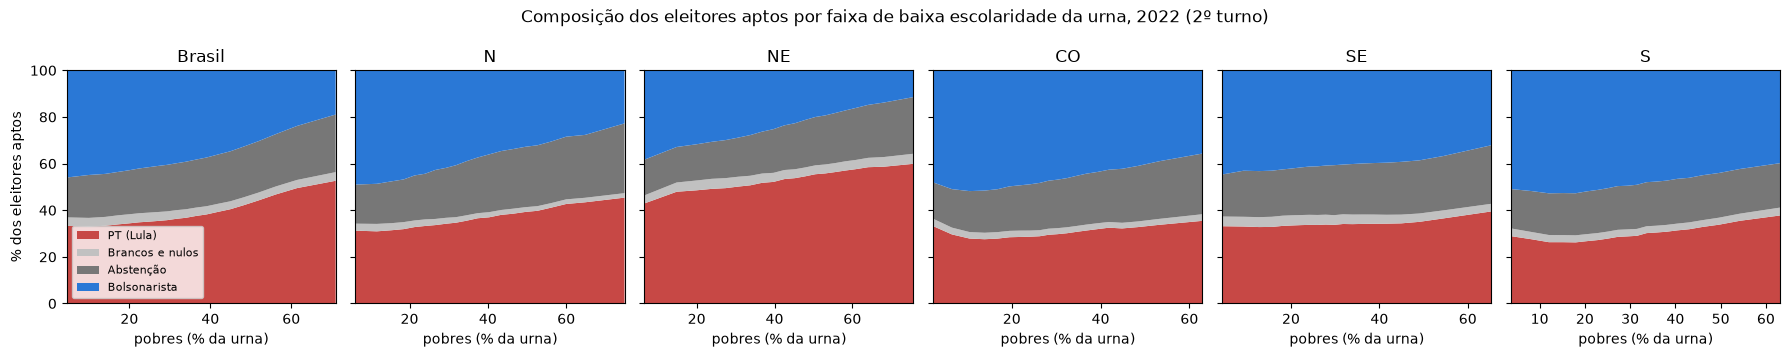

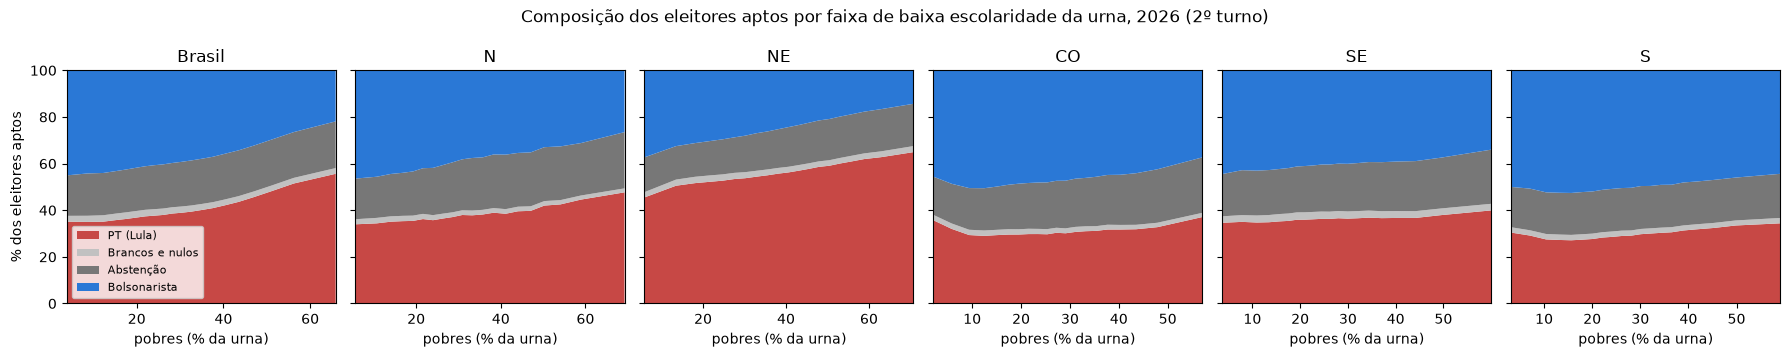

In [9]:
def faixas(d, k=20):
    d = d.sort_values("pobres")
    cum = d["qt_aptos"].cumsum() / d["qt_aptos"].sum()
    g = np.minimum((cum * k).astype(int), k - 1)
    soma = d.groupby(g)[["qt_pt", "qt_bolso", "qt_brancos_nulos", "qt_abstencao", "qt_aptos"]].sum()
    out = 100 * soma[["qt_pt", "qt_bolso", "qt_brancos_nulos", "qt_abstencao"]].div(soma["qt_aptos"], axis=0)
    out.columns = list(PARTES)
    out["pobres"] = d.groupby(g).apply(lambda s: np.average(s["pobres"], weights=s["qt_aptos"]), include_groups=False)
    return out


ORDEM = ["pc_aptos_pt", "pc_aptos_branco_nulo", "pc_aptos_abstencao", "pc_aptos_bolso"]
GRUPOS = [("Brasil", None), ("N", "N"), ("NE", "NE"), ("CO", "CO"), ("SE", "SE"), ("S", "S")]
for ano, d in base.items():
    fig, eixos = plt.subplots(1, 6, figsize=(18, 3.6), sharey=True)
    for ax, (nome, reg_) in zip(eixos, GRUPOS):
        f = faixas(d if reg_ is None else d.loc[d["regiao"] == reg_])
        ax.stackplot(f["pobres"], [f[c] for c in ORDEM], colors=[COR[c] for c in ORDEM], labels=[PARTES[c] for c in ORDEM], linewidth=0)
        ax.set_title(nome)
        ax.set_xlabel("pobres (% da urna)")
        ax.set_ylim(0, 100)
        ax.margins(x=0)
    eixos[0].set_ylabel("% dos eleitores aptos")
    eixos[0].legend(loc="lower left", fontsize=8, frameon=True)
    fig.suptitle(f"Composição dos eleitores aptos por faixa de baixa escolaridade da urna, {ano} (2º turno)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"composicao_aptos_{ano}.png", dpi=150)
    plt.show()

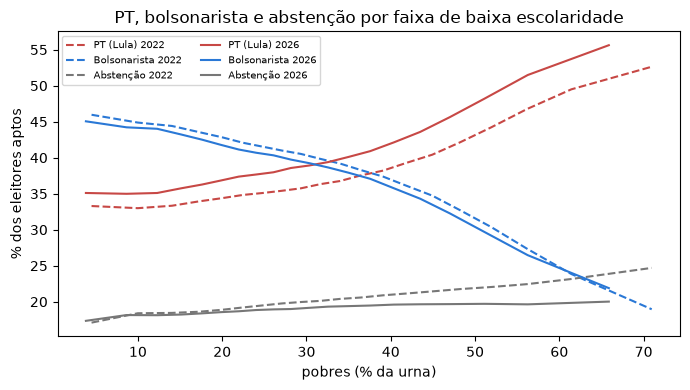

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
estilo = {2022: "--", 2026: "-"}
for ano, d in base.items():
    f = faixas(d)
    for c in ("pc_aptos_pt", "pc_aptos_bolso", "pc_aptos_abstencao"):
        ax.plot(f["pobres"], f[c], estilo[ano], color=COR[c], label=f"{PARTES[c]} {ano}")
ax.set_xlabel("pobres (% da urna)")
ax.set_ylabel("% dos eleitores aptos")
ax.set_title("PT, bolsonarista e abstenção por faixa de baixa escolaridade")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "linhas_2022_2026.png", dpi=150)
plt.show()

## 8. Notas para a leitura

- **Voto facultativo**: analfabetos (parte de `pobres`) e maiores de 70 anos votam
  se quiserem. Parte da abstenção maior nas urnas de baixa escolaridade é legal e
  demográfica; a especificação (d) controla o % de voto facultativo da urna.
- **Cadastro**: a abstenção inclui quem morreu ou mudou sem sair do cadastro,
  mais comum em área de emigração. O efeito fixo de município e a mudança na mesma
  urna reduzem, mas não eliminam, essa parte.
- **Escolaridade desatualizada**: a do cadastro é a do alistamento.
- **PIB**: PIB municipal de 2022 (eleição de 2022) e 2023 (eleição de 2026), sobre a
  população do Censo 2022.
- **Urnas excluídas**: exterior, voto em trânsito, presos provisórios e urnas sem
  resultado (ver a aba `excluidas` da planilha e `urna_aptos_base.ipynb`).